# II.B — Machine learning for target-coin ranking

**Objective (brief II.B).** One hour before a pump, rank the coins of the exchange by their probability of being
the target.
1. Describe every (event, candidate) pair with four feature families: coin (CoinGecko, 3 days before), market
   (returns and volumes on $[\tau-(x+1)\,\text{h},\ \tau-1\,\text{h}]$), channel history, and interactions such as the
   distance to the barycentre of the channel's past targets.
2. Train a logistic regression, a random forest and LightGBM, and handle the imbalance (about 0.5 % positives) by
   class weighting, undersampling, or a softmax loss computed per event.
3. Evaluate with HR@$k$ and AUC-PR, interpret with SHAP values, and compare the two best models with McNemar's
   test or a paired bootstrap.

**Protocol (brief, mandatory).** Chronological split identical to [A1]: train $\tau<$ 2021-01-19, validation up to
2021-05-10, test afterwards. Every feature is computable at $\tau-1$ h. Hyperparameters are chosen on validation;
the selected model is refit on train + validation and the test set is used **once**. Results are averaged over
seeds (2 in the QUICK run, 5 in the full run) and reported as mean ± standard deviation.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import shap
from scipy import optimize
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pnd_paper import settings, metrics
from pnd_paper import stats as S
from pnd_paper import ranking_dataset as rd
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
settings.seed_everything()
R = Reporter("IIB_machine_learning")
SZ = settings.SIZES

## 1. The ranking dataset

For event $i$ (channel $h_i$, target $c^\star_i$, time $\tau_i$) the candidate set $\mathcal C_i$ contains the Binance
BTC-quoted coins trading during the 72 hours before $\tau_i-1$ h (see I.0). Each pair $(i,c)$, $c\in\mathcal C_i$, is a
row with label $y_{ic}=\mathbf 1\{c=c^\star_i\}$. Notation: $t_i$ is the last complete hourly bar before
$\tau_i-1$ h, $P$ the close price in BTC and $Q$ the quote volume.

| family | features |
|---|---|
| coin (CoinGecko, $\tau-3$ d) | $\log$ market cap (USD, BTC), $\log$ price, $\log$ volume, $\log(1+\text{Twitter})$, $\log(1+\text{Reddit})$, $\log$ Alexa rank |
| market, $x\in\{1,3,6,12,24,48,60,72\}$ | $r^{(x)}=\log P_{t}-\log P_{t-x}$; $\log(1+\sum_{s=t-x+1}^{t}Q_s)$; relative volume $\log\big(\bar Q_{(x)}/\bar Q_{[t-30\text{d},t-72\text{h}]}\big)$; 24 h volatility, taker-buy share, max hourly return over 72 h, $\log P_t$ |
| channel history (before $\tau-1$ h) | number of past pumps of the channel; pumps of $c$ by the channel and by all channels (all time, 30 days); $\log$ hours since the last pump of $c$ |
| interaction | $\lVert\boldsymbol z_c-\bar{\boldsymbol z}_{h}\rVert_2$, distance from $c$'s standardised coin vector to the barycentre of the channel's past targets; $|\log\text{mcap}_c-\overline{\log\text{mcap}}_{h}|$ |

In [2]:
ev = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
df = rd.build(ev, panels).sort_values(["event_id", "symbol"]).reset_index(drop=True)
FEATS = rd.feature_columns(df)
FAMILY = {f: {"g": "coin", "m": "market", "h": "history", "i": "interaction"}[f[0]] for f in FEATS}
sizes = df.groupby("split").agg(events=("event_id", "nunique"), rows=("label", "size"), positives=("label", "sum"))
sizes["positive ratio"] = sizes.positives / sizes.rows
sizes = sizes.reindex(["train", "valid", "test"])
sizes.loc["paper [A1] (Table 4)"] = [np.nan, 196_613 / 1, 948, 0.0048]
sizes.loc["paper [A1] (Table 4)", "events"] = 948
R.table(sizes, "dataset_sizes")
show(sizes, "{:.4g}")
md(f"{len(FEATS)} features. Events per split: train {sizes.loc['train', 'events']:.0f}, valid "
   f"{sizes.loc['valid', 'events']:.0f}, test {sizes.loc['test', 'events']:.0f}; the paper reports 648 / 100 / 200 positives "
   "(Table 4), so our population matches the paper's almost exactly.")

,events,rows,positives,positive ratio
split,,,,
train,648,1.104e+05,648,0.005867
valid,100,2.516e+04,100,0.003974
test,199,5.711e+04,199,0.003485
paper [A1] (Table 4),948,1.966e+05,948,0.0048


46 features. Events per split: train 648, valid 100, test 199; the paper reports 648 / 100 / 200 positives (Table 4), so our population matches the paper's almost exactly.

### Leakage checks

* **Time.** Market features end at $t_i$ (before $\tau_i-1$ h); history features use pumps before $\tau_i-1$ h only.
* **Relays.** A pump announced late by a relay channel could reveal a pump that already happened. Only a handful of
  targets were pumped by another channel in the 24 hours before (table below), so this channel of leakage is
  negligible.
* **Source asymmetry.** Target coins' CoinGecko records come from one file and candidates' from another; a feature
  whose missingness differs between labels would let a model identify the source rather than the target. The table
  lists missing rates by label.

In [3]:
tg = df[df.label == 1]
rec = np.expm1(tg.h_gl_cand_recency)
leak = pd.DataFrame({"targets pumped by any channel in the previous 24 h": [(rec <= 24).sum()],
                     "targets pumped before (any channel, any time)": [(tg.h_gl_cand_count > 0).mean()],
                     "targets pumped before by the same channel": [(tg.h_ch_cand_count > 0).mean()]}).T
show(leak.rename(columns={0: "value"}), "{:.3f}")
miss = df.groupby("label")[FEATS].apply(lambda d: d.isna().mean()).T
miss.columns = ["missing (candidates)", "missing (targets)"]
miss = miss[(miss.max(axis=1) > 0)]
R.table(miss, "missingness_by_label")
show(miss, "{:.3f}")
md("Missingness is similar for targets and candidates (largest gap: Reddit, a few points), so the CoinGecko "
   "source does not reveal the label. The share of targets already pumped before (re-pumps) is the paper's main "
   "regularity: [A1] reports a 60.1 % re-pump probability.")

,value
targets pumped by any channel in the previous 24 h,12.000
"targets pumped before (any channel, any time)",0.740
targets pumped before by the same channel,0.200


,missing (candidates),missing (targets)
g_log_mcap_usd,0.102,0.121
g_log_mcap_btc,0.102,0.121
g_log_price_usd,0.076,0.067
g_log_price_btc,0.076,0.067
g_log_vol_usd,0.076,0.067
g_log_vol_btc,0.076,0.067
g_log_twitter,0.219,0.184
g_log_reddit,0.318,0.265
g_log_alexa,0.107,0.131
m_ret_1h,0.001,0.001


Missingness is similar for targets and candidates (largest gap: Reddit, a few points), so the CoinGecko source does not reveal the label. The share of targets already pumped before (re-pumps) is the paper's main regularity: [A1] reports a 60.1 % re-pump probability.

## 2. Models and imbalance strategies

Let $s_\theta(i,c)$ be the score of candidate $c$ for event $i$.

* **Logistic regression (LR).** $P(y=1\mid x)=\sigma(w^\top x+b)$, loss
  $-\sum_{ic}\omega_{y}\,[y\log\sigma+(1-y)\log(1-\sigma)]+\frac{1}{2C}\lVert w\rVert^2$, with median imputation plus
  missing indicators and standardisation.
* **Conditional logit (LR-softmax).** The per-event softmax loss of the brief,
  $$\mathcal L=-\sum_i\log\frac{e^{s(c^\star_i)}}{\sum_{c\in\mathcal C_i}e^{s(c)}},\qquad s(c)=w^\top x_{ic},$$
  compares the target only with its own competitors, which removes the imbalance problem: every event contributes
  exactly one term. It is fitted with L-BFGS on the analytic gradient
  $\nabla_w\mathcal L=\sum_i\big(\sum_c p_{ic}x_{ic}-x_{ic^\star_i}\big)+\lambda w$.
* **Random forest (RF)** of CART trees (Gini impurity), bootstrap samples and random feature subsets.
* **LightGBM**, gradient-boosted trees; with the binary loss or with the per-event softmax loss as a custom objective
  (gradient $p_{ic}-y_{ic}$, Hessian $p_{ic}(1-p_{ic})$ per event).

**Imbalance.** Class weights $\omega_1/\omega_0=n_0/n_1$ ("balanced"); random undersampling of negatives to $r$ per
positive in each training event; or the softmax loss. For LR, RF and binary LightGBM the strategy is itself a
hyperparameter of the search.

**Hyperparameter search.** Optuna's TPE sampler (a sequential Bayesian optimiser modelling $p(\theta\mid\text{good})$
against $p(\theta\mid\text{bad})$) maximises the validation MRR $=\frac1N\sum_i 1/\rho_i$, a smooth summary of the
whole ranking. The search spaces are much wider than the paper's (it gives none). Number of trials per model:

In [4]:
md(f"**{SZ.optuna_trials} trials** per model ({'QUICK' if settings.QUICK else 'FULL'} run).")
train, valid, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "valid", "test"))
trval = pd.concat([train, valid], ignore_index=True)


def undersample(d, ratio, seed):
    if ratio is None:
        return d
    rng = np.random.default_rng(seed)
    key = rng.random(len(d))
    neg = d.label.values == 0
    rank = pd.Series(np.where(neg, key, -1.0)).groupby(d.event_id.values).rank(method="first")
    keep = (~neg) | (rank.values <= ratio)
    return d[keep].reset_index(drop=True)


def evaluate(d, scores):
    out = d[["event_id", "label"]].copy()
    out["score"] = scores
    return metrics.ranking_report(out), out


# ---------- LR
def fit_lr(d, prm, seed):
    d = undersample(d, prm["ratio"], seed)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(C=prm["C"], class_weight=prm["cw"], max_iter=2000))
    return model.fit(d[FEATS], d.label)


def lr_space(t):
    return {"C": t.suggest_float("C", 1e-4, 1e2, log=True), "cw": t.suggest_categorical("cw", [None, "balanced"]),
            "ratio": t.suggest_categorical("ratio", [None, 5, 20, 50])}


# ---------- conditional logit
class CondLogit:
    def __init__(self, lam):
        self.lam = lam

    def fit(self, d):
        self.prep = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()).fit(d[FEATS])
        X = self.prep.transform(d[FEATS])
        X = np.c_[X]
        starts = np.r_[0, np.flatnonzero(np.diff(d.event_id.values)) + 1]
        pos = np.flatnonzero(d.label.values == 1)
        G = len(starts)

        def f(w):
            s = X @ w
            mx = np.maximum.reduceat(s, starts)
            e = np.exp(s - np.repeat(mx, np.diff(np.r_[starts, len(s)])))
            Z = np.add.reduceat(e, starts)
            lse = mx + np.log(Z)
            p = e / np.repeat(Z, np.diff(np.r_[starts, len(s)]))
            loss = (lse.sum() - s[pos].sum()) / G + 0.5 * self.lam * w @ w
            grad = (X.T @ p - X[pos].sum(0)) / G + self.lam * w
            return loss, grad

        self.w = optimize.minimize(f, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", options={"maxiter": 500}).x
        return self

    def score(self, d):
        return self.prep.transform(d[FEATS]) @ self.w


def fit_cl(d, prm, seed):
    return CondLogit(prm["lam"]).fit(d)


def cl_space(t):
    return {"lam": t.suggest_float("lam", 1e-6, 1.0, log=True)}


# ---------- RF
def fit_rf(d, prm, seed):
    d = undersample(d, prm["ratio"], seed)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                          RandomForestClassifier(n_estimators=prm["n"], max_depth=prm["depth"], min_samples_leaf=prm["leaf"],
                                                 max_features=prm["mf"], class_weight=prm["cw"], n_jobs=-1, random_state=seed))
    return model.fit(d[FEATS], d.label)


def rf_space(t):
    return {"n": t.suggest_int("n", 100, 600, step=100), "depth": t.suggest_categorical("depth", [4, 8, 12, 16, 24, None]),
            "leaf": t.suggest_int("leaf", 1, 200, log=True), "mf": t.suggest_categorical("mf", ["sqrt", 0.2, 0.4, 0.7]),
            "cw": t.suggest_categorical("cw", [None, "balanced_subsample"]), "ratio": t.suggest_categorical("ratio", [5, 20, 50])}


# ---------- LightGBM
def softmax_obj(preds, data):
    y = data.get_label()
    grp = data.get_group()
    starts = np.r_[0, np.cumsum(grp)[:-1]].astype(int)
    lens = np.asarray(grp, int)
    mx = np.maximum.reduceat(preds, starts)
    e = np.exp(preds - np.repeat(mx, lens))
    p = e / np.repeat(np.add.reduceat(e, starts), lens)
    return p - y, np.maximum(p * (1 - p), 1e-6)


def fit_lgb(d, prm, seed, objective="binary"):
    if objective == "binary":
        d = undersample(d, prm.get("ratio"), seed)
    params = {"learning_rate": prm["lr"], "num_leaves": prm["leaves"], "min_child_samples": prm["mcs"],
              "feature_fraction": prm["ff"], "bagging_fraction": prm["bf"], "bagging_freq": 1, "lambda_l2": prm["l2"],
              "lambda_l1": prm["l1"], "max_depth": -1, "verbose": -1, "seed": seed, "num_threads": 0}
    if objective == "binary":
        params["objective"] = "binary"
        if prm.get("spw"):
            params["scale_pos_weight"] = (d.label == 0).sum() / max((d.label == 1).sum(), 1)
        ds = lgb.Dataset(d[FEATS], d.label)
    else:
        params["objective"] = softmax_obj
        ds = lgb.Dataset(d[FEATS], d.label, group=d.groupby("event_id", sort=False).size().values)
    return lgb.train(params, ds, num_boost_round=prm["n"])


def lgb_space(t, objective="binary"):
    prm = {"lr": t.suggest_float("lr", 0.005, 0.3, log=True), "leaves": t.suggest_int("leaves", 4, 128, log=True),
           "mcs": t.suggest_int("mcs", 5, 500, log=True), "ff": t.suggest_float("ff", 0.3, 1.0),
           "bf": t.suggest_float("bf", 0.4, 1.0), "l2": t.suggest_float("l2", 1e-8, 10.0, log=True),
           "l1": t.suggest_float("l1", 1e-8, 10.0, log=True), "n": t.suggest_int("n", 50, 1000, log=True)}
    if objective == "binary":
        prm["ratio"] = t.suggest_categorical("ratio", [None, 5, 20, 50])
        prm["spw"] = t.suggest_categorical("spw", [False, True])
    return prm


def predict(model, d):
    if isinstance(model, CondLogit):
        return model.score(d)
    if isinstance(model, lgb.Booster):
        return model.predict(d[FEATS], raw_score=True)
    return model.predict_proba(d[FEATS])[:, 1]


MODELS = {
    "LR": (fit_lr, lr_space),
    "LR-softmax": (fit_cl, cl_space),
    "RF": (fit_rf, rf_space),
    "LightGBM": (lambda d, p, s: fit_lgb(d, p, s, "binary"), lambda t: lgb_space(t, "binary")),
    "LightGBM-softmax": (lambda d, p, s: fit_lgb(d, p, s, "softmax"), lambda t: lgb_space(t, "softmax")),
}

**25 trials** per model (QUICK run).

## 3. Hyperparameter search on the validation set

In [5]:
best_params, search_hist = {}, {}
for name, (fit, space) in MODELS.items():
    def objective(trial, fit=fit, space=space):
        prm = space(trial)
        model = fit(train, prm, settings.SEED)
        rep, _ = evaluate(valid, predict(model, valid))
        trial.set_user_attr("HR@10", rep["HR@10"])
        return rep["MRR"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=settings.SEED))
    study.optimize(objective, n_trials=SZ.optuna_trials if name != "LR-softmax" else max(10, SZ.optuna_trials // 2))
    best_params[name] = study.best_params
    search_hist[name] = study.trials_dataframe()[["number", "value", "user_attrs_HR@10"]]
search = pd.DataFrame({n: {"best validation MRR": search_hist[n].value.max(),
                           "validation HR@10 at best": search_hist[n].loc[search_hist[n].value.idxmax(), "user_attrs_HR@10"],
                           "trials": len(search_hist[n]), "best hyperparameters": str(best_params[n])} for n in MODELS}).T
R.table(search, "hyperparameter_search")
show(search)

,best validation MRR,validation HR@10 at best,trials,best hyperparameters
LR,0.2715,0.56,25,"{'C': 0.005715545708399059, 'cw': None, 'ratio': 5}"
LR-softmax,0.271,0.56,12,{'lam': 0.18013404791374119}
RF,0.2491,0.41,25,"{'n': 600, 'depth': 16, 'leaf': 102, 'mf': 0.7, 'cw': None, 'ratio': 5}"
LightGBM,0.1604,0.33,25,"{'lr': 0.005780963646032276, 'leaves': 74, 'mcs': 7, 'ff': 0.5499781777768239, 'bf': 0.8132973726583357, 'l2': 0.008696106668306851, 'l1': 3.073142992167156e-07, 'n': 265, 'ratio': 5, 'spw': True}"
LightGBM-softmax,0.2022,0.43,25,"{'lr': 0.16359657166149869, 'leaves': 78, 'mcs': 118, 'ff': 0.9044404688162424, 'bf': 0.5492267840615412, 'l2': 0.00035839155722047425, 'l1': 3.070364563117169e-08, 'n': 84}"


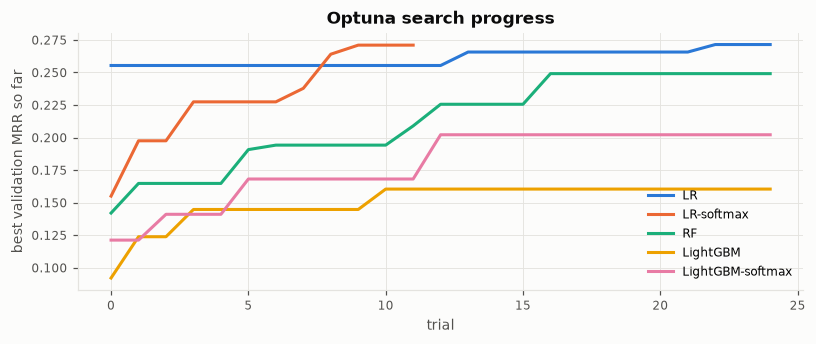

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, (n, h) in enumerate(search_hist.items()):
    ax.plot(h.number, h.value.cummax(), color=SERIES[i], label=n)
ax.set_xlabel("trial")
ax.set_ylabel("best validation MRR so far")
ax.set_title("Optuna search progress")
ax.legend()
R.fig(fig, "search_progress")
close(fig)

## 4. Test-set evaluation (refit on train + validation, one pass on test)

HR@$k=\frac1N\sum_i\mathbf 1\{\rho_i\le k\}$ with $\rho_i$ the rank of the true target among $\mathcal C_i$ (ties
counted as half), AUC-PR (average precision, the area under the precision–recall curve of all pairs pooled) and
ROC-AUC. A random ranking gives $\mathbb E[\mathrm{HR}@k]=\frac1N\sum_i\min(k,|\mathcal C_i|)/|\mathcal C_i|$.

In [7]:
seeds = [settings.SEED + s for s in range(SZ.seeds)]
test_reports, test_scores = {}, {}
for name, (fit, _) in MODELS.items():
    reps = []
    for sd in seeds:
        model = fit(trval, dict(best_params[name]) if name != "LR" else {**best_params[name]}, sd)
        rep, sc = evaluate(test, predict(model, test))
        reps.append(rep)
        if sd == seeds[0]:
            test_scores[name] = sc
            if name == "LightGBM-softmax":
                lgb_final = model
            if name == "LR":
                lr_final = model
    test_reports[name] = pd.DataFrame(reps)
rand = metrics.random_baseline(test)
cols = [f"HR@{k}" for k in settings.HR_KS] + ["MRR", "AUC-PR", "AUC"]
mean = pd.DataFrame({n: r[cols].mean() for n, r in test_reports.items()}).T
std = pd.DataFrame({n: r[cols].std(ddof=1) for n, r in test_reports.items()}).T.fillna(0.0)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
table.loc["random ranking"] = pd.Series({**{k: f"{v:.3f}" for k, v in rand.items()}, "MRR": "", "AUC-PR": "", "AUC": "0.5"})
R.table(mean, "test_mean")
R.table(std, "test_std")
R.table(table, "test_table")
show(table)

,HR@1,HR@3,HR@5,HR@10,HR@20,HR@30,MRR,AUC-PR,AUC
LR,0.085 ± 0.043,0.284 ± 0.011,0.372 ± 0.028,0.543 ± 0.007,0.751 ± 0.025,0.819 ± 0.007,0.232 ± 0.022,0.055 ± 0.002,0.911 ± 0.001
LR-softmax,0.131 ± 0.0,0.246 ± 0.0,0.317 ± 0.0,0.528 ± 0.0,0.769 ± 0.0,0.824 ± 0.0,0.247 ± 0.0,0.057 ± 0.0,0.91 ± 0.0
RF,0.153 ± 0.039,0.319 ± 0.004,0.41 ± 0.025,0.535 ± 0.011,0.678 ± 0.057,0.799 ± 0.007,0.278 ± 0.015,0.114 ± 0.022,0.904 ± 0.002
LightGBM,0.143 ± 0.004,0.334 ± 0.039,0.405 ± 0.032,0.603 ± 0.028,0.736 ± 0.025,0.822 ± 0.025,0.291 ± 0.007,0.115 ± 0.007,0.917 ± 0.001
LightGBM-softmax,0.098 ± 0.053,0.183 ± 0.082,0.244 ± 0.082,0.339 ± 0.06,0.533 ± 0.071,0.621 ± 0.089,0.186 ± 0.064,0.042 ± 0.028,0.866 ± 0.041
random ranking,0.003,0.010,0.017,0.035,0.070,0.105,,,0.5


### Comparison with [A1] (Table 5, test set)

,ours HR@1,[A1] HR@1,ours HR@10,[A1] HR@10,ours HR@30,[A1] HR@30
model,,,,,,
LR,0.085,0.156,0.543,0.449,0.819,0.662
RF,0.153,0.189,0.535,0.537,0.799,0.731
LightGBM,0.143,nan,0.603,nan,0.822,nan
LightGBM-softmax,0.098,nan,0.339,nan,0.621,nan
LR-softmax,0.131,nan,0.528,nan,0.824,nan


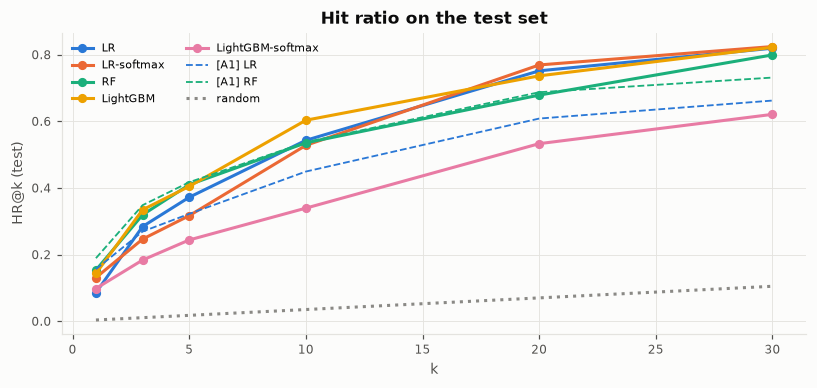

In [8]:
paper = settings.PAPER_TABLE5[["LR", "RF"]].T
cmp_rows = []
for ours, theirs in (("LR", "LR"), ("RF", "RF"), ("LightGBM", None), ("LightGBM-softmax", None), ("LR-softmax", None)):
    row = {"model": ours}
    for k in (1, 3, 5, 10, 20, 30):
        row[f"ours HR@{k}"] = mean.loc[ours, f"HR@{k}"]
        row[f"[A1] HR@{k}"] = paper.loc[theirs, f"HR@{k}"] if theirs else np.nan
    cmp_rows.append(row)
cmp_tab = pd.DataFrame(cmp_rows).set_index("model")
R.table(cmp_tab, "comparison_with_paper")
show(cmp_tab[[c for c in cmp_tab.columns if "@1" in c and "@10" not in c] + [c for c in cmp_tab.columns if "@10" in c]
             + [c for c in cmp_tab.columns if "@30" in c]], "{:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ks = list(settings.HR_KS)
for i, n in enumerate(MODELS):
    ax.plot(ks, [mean.loc[n, f"HR@{k}"] for k in ks], marker="o", color=SERIES[i], label=n)
ax.plot(ks, settings.PAPER_TABLE5["LR"].values, ls="--", color=SERIES[0], lw=1.2, label="[A1] LR")
ax.plot(ks, settings.PAPER_TABLE5["RF"].values, ls="--", color=SERIES[2], lw=1.2, label="[A1] RF")
ax.plot(ks, [rand[f"HR@{k}"] for k in ks], ls=":", color="#8a8985", label="random")
ax.set_xlabel("k")
ax.set_ylabel("HR@k (test)")
ax.set_title("Hit ratio on the test set")
ax.legend(ncol=2, fontsize=7)
R.fig(fig, "hr_curves")
close(fig)

## 5. Imbalance strategies (LightGBM, best tree parameters fixed)

Holding the tree hyperparameters of the best softmax model fixed, we change only the way imbalance is handled and
report the **validation** metrics (the test set is not used for this choice).

In [9]:
base = {k: v for k, v in best_params["LightGBM-softmax"].items()}
strategies = {"binary, no correction": {**base, "ratio": None, "spw": False},
              "binary, class weights": {**base, "ratio": None, "spw": True},
              "binary, undersampling 1:20": {**base, "ratio": 20, "spw": False},
              "binary, undersampling 1:5": {**base, "ratio": 5, "spw": False}}
imb = {n: evaluate(valid, predict(fit_lgb(train, p, settings.SEED, "binary"), valid))[0] for n, p in strategies.items()}
imb["per-event softmax"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
imb = pd.DataFrame(imb).T[["HR@1", "HR@5", "HR@10", "HR@30", "MRR", "AUC-PR"]]
R.table(imb, "imbalance_strategies")
show(imb, "{:.3f}")

,HR@1,HR@5,HR@10,HR@30,MRR,AUC-PR
"binary, no correction",0.000,0.120,0.170,0.460,0.070,0.013
"binary, class weights",0.040,0.070,0.130,0.340,0.070,0.016
"binary, undersampling 1:20",0.070,0.130,0.190,0.430,0.121,0.016
"binary, undersampling 1:5",0.020,0.060,0.160,0.560,0.077,0.017
per-event softmax,0.110,0.270,0.430,0.690,0.202,0.043


## 6. Interpretation with SHAP

For a model $f$ and an instance $x$, the SHAP value of feature $j$ is its Shapley value in the cooperative game
$v(S)=\mathbb E[f(X)\mid X_S=x_S]$:
$$\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!\,(|F|-|S|-1)!}{|F|!}\big[v(S\cup\{j\})-v(S)\big],
\qquad f(x)=\phi_0+\sum_j\phi_j.$$
TreeSHAP computes it exactly for tree ensembles; for the linear model, $\phi_j=w_j(x_j-\mathbb E x_j)$
(LinearExplainer). We explain the raw score of the softmax LightGBM on the test set.

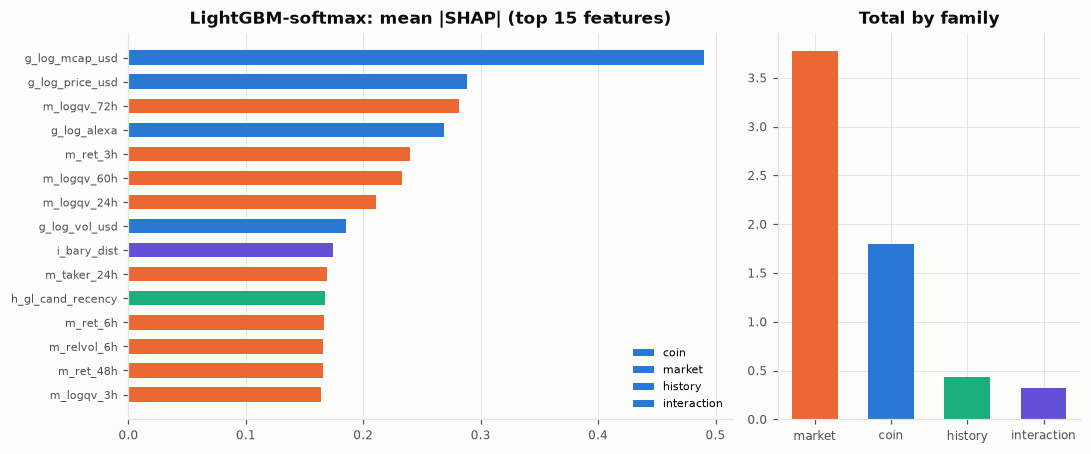

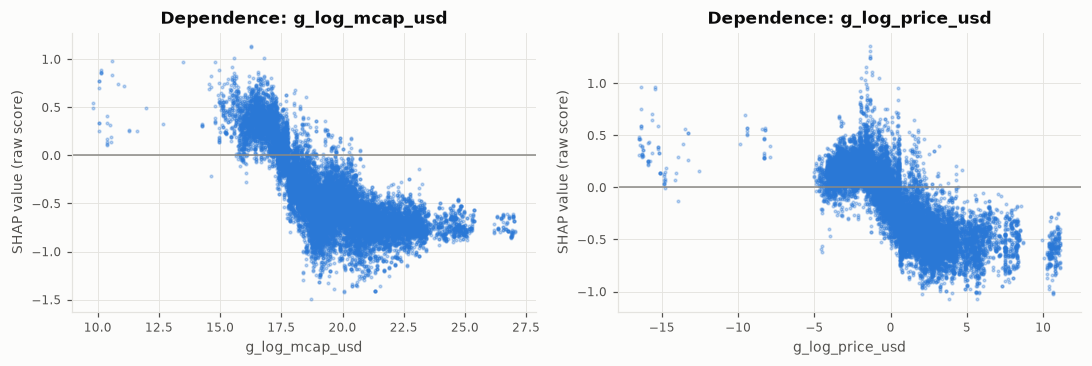

,LightGBM-softmax,mean |SHAP| (LGBM),LR,mean |SHAP| (LR)
0,g_log_mcap_usd,0.490,i_bary_dist,0.229
1,g_log_price_usd,0.288,h_gl_cand_recency,0.166
2,m_logqv_72h,0.281,g_log_mcap_usd,0.153
3,g_log_alexa,0.269,i_mcap_gap,0.141
4,m_ret_3h,0.240,m_ret_60h,0.124
5,m_logqv_60h,0.233,g_log_price_btc,0.122
6,m_logqv_24h,0.211,h_gl_cand_count,0.117
7,g_log_vol_usd,0.185,g_log_vol_usd,0.110
8,i_bary_dist,0.175,g_log_alexa,0.109
9,m_taker_24h,0.169,m_ret_6h,0.104


In [10]:
Xs = test[FEATS].sample(min(20000, len(test)), random_state=settings.SEED)
sv = shap.TreeExplainer(lgb_final).shap_values(Xs)
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
fam_imp = imp.groupby(imp.index.map(FAMILY)).sum().sort_values(ascending=False)
R.table(imp.rename("mean |SHAP|").to_frame(), "shap_importance")
fam_color = {"coin": SERIES[0], "market": SERIES[1], "history": SERIES[2], "interaction": SERIES[6]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [2, 1]})
top = imp.head(15)[::-1]
axes[0].barh(top.index, top.values, color=[fam_color[FAMILY[f]] for f in top.index], height=0.6)
axes[0].set_title("LightGBM-softmax: mean |SHAP| (top 15 features)")
axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=7)
for fam, c in fam_color.items():
    axes[0].barh([], [], color=c, label=fam)
axes[0].legend(fontsize=7, loc="lower right")
axes[1].bar(fam_imp.index, fam_imp.values, color=[fam_color[f] for f in fam_imp.index], width=0.6)
axes[1].set_title("Total by family")
R.fig(fig, "shap_importance")
close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, f in zip(axes, imp.index[:2]):
    j = FEATS.index(f)
    ax.scatter(Xs[f], sv[:, j], s=3, alpha=0.3, color=fam_color[FAMILY[f]])
    ax.axhline(0, color="#8a8985", lw=1)
    ax.set_xlabel(f)
    ax.set_ylabel("SHAP value (raw score)")
    ax.set_title(f"Dependence: {f}")
R.fig(fig, "shap_dependence")
close(fig)

lr_step = lr_final.named_steps["logisticregression"]
Xt = lr_final[:-1].transform(test[FEATS].iloc[:5000])
lin = shap.LinearExplainer(lr_step, Xt).shap_values(Xt)
names_lr = list(FEATS) + [f"missing({FEATS[i]})" for i in lr_final.named_steps["simpleimputer"].indicator_.features_]
lin_imp = pd.Series(np.abs(lin).mean(0), index=names_lr).sort_values(ascending=False)
R.table(lin_imp.rename("mean |SHAP|").to_frame(), "shap_importance_lr")
show(pd.DataFrame({"LightGBM-softmax": imp.head(10).index, "mean |SHAP| (LGBM)": imp.head(10).values,
                   "LR": lin_imp.head(10).index, "mean |SHAP| (LR)": lin_imp.head(10).values}), "{:.3f}")

### Feature-family ablation (validation)

Removing one family at a time and refitting the softmax LightGBM measures how much each family adds given the
others (SHAP measures how much the model *uses* a feature, which is not the same thing when features are
correlated).

In [11]:
abl = {}
for fam in ["coin", "market", "history", "interaction"]:
    keep = [f for f in FEATS if FAMILY[f] != fam]
    saved = FEATS
    FEATS = keep
    abl[f"without {fam}"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
    FEATS = saved
abl["all features"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
abl = pd.DataFrame(abl).T[["HR@1", "HR@10", "HR@30", "MRR"]]
R.table(abl, "family_ablation")
show(abl, "{:.3f}")

,HR@1,HR@10,HR@30,MRR
without coin,0.020,0.260,0.440,0.088
without market,0.000,0.140,0.480,0.064
without history,0.090,0.200,0.380,0.133
without interaction,0.010,0.270,0.580,0.094
all features,0.110,0.430,0.690,0.202


## 7. Is the best model significantly better than the runner-up?

On the test events, let $a_i=\mathbf 1\{\rho^A_i\le k\}$ and $b_i=\mathbf 1\{\rho^B_i\le k\}$.

* **McNemar (exact)** on HR@1: under $H_0:P(a=1,b=0)=P(a=0,b=1)$, $n_{10}\mid n_{10}+n_{01}\sim\mathrm{Bin}(\cdot,1/2)$.
* **Paired bootstrap** on HR@10 and on MRR: resample events with replacement, $B=10\,000$; the two-sided p-value is
  the share of centred bootstrap differences at least as extreme as the observed one.

In [12]:
order_ = mean["MRR"].sort_values(ascending=False).index.tolist()
A, Bm = order_[0], order_[1]
ra = metrics.target_ranks(test_scores[A])
rb = metrics.target_ranks(test_scores[Bm]).reindex(ra.index)
mc = S.mcnemar(ra <= 1, rb <= 1)
bt10 = S.paired_bootstrap_diff((ra <= 10).astype(float), (rb <= 10).astype(float))
btm = S.paired_bootstrap_diff(1 / ra, 1 / rb)
sig = pd.DataFrame({"comparison": [f"{A} vs {Bm}"] * 3, "metric": ["HR@1 (McNemar)", "HR@10 (paired bootstrap)", "MRR (paired bootstrap)"],
                    "difference": [(ra <= 1).mean() - (rb <= 1).mean(), bt10["diff"], btm["diff"]],
                    "95% CI": ["", f"[{bt10['ci_low']:.3f}, {bt10['ci_high']:.3f}]", f"[{btm['ci_low']:.3f}, {btm['ci_high']:.3f}]"],
                    "p": [mc["p"], bt10["p"], btm["p"]]})
R.table(sig, "significance", index=False)
show(sig.set_index("metric"))
md(f"Best two models by test MRR: **{A}** and **{Bm}**. McNemar on HR@1: $n_{{10}}={mc['n10']}$, $n_{{01}}={mc['n01']}$, "
   f"${S.fmt_p(mc['p'])}$ → {S.decision(mc['p'])}. Paired bootstrap on HR@10: difference {bt10['diff']:+.3f}, "
   f"${S.fmt_p(bt10['p'])}$ → {S.decision(bt10['p'])}; on MRR: {btm['diff']:+.3f}, ${S.fmt_p(btm['p'])}$.")

best_vs_rand = S.paired_bootstrap_diff((ra <= 10).astype(float), np.full(len(ra), rand["HR@10"]))
md(f"Against a random ranking, {A} improves HR@10 by {best_vs_rand['diff']:+.3f} "
   f"(95 % CI [{best_vs_rand['ci_low']:.3f}, {best_vs_rand['ci_high']:.3f}]).")

,comparison,difference,95% CI,p
metric,,,,
HR@1 (McNemar),LightGBM vs RF,-0.0402,,0.1849
HR@10 (paired bootstrap),LightGBM vs RF,0.05528,"[0.020, 0.095]",0.008199
MRR (paired bootstrap),LightGBM vs RF,0.007975,"[-0.025, 0.041]",0.6336


Best two models by test MRR: **LightGBM** and **RF**. McNemar on HR@1: $n_{10}=10$, $n_{01}=18$, $p=0.185$ → do not reject $H_0$ at $\alpha=0.05$. Paired bootstrap on HR@10: difference +0.055, $p=0.008$ → reject $H_0$ at $\alpha=0.05$; on MRR: +0.008, $p=0.634$.

Against a random ranking, LightGBM improves HR@10 by +0.548 (95 % CI [0.478, 0.618]).

## 8. Interpretation (QUICK run: 25 trials per model, 2 seeds)

* **The target is predictable far beyond chance.** Every model ranks the true target in its top 10 for 53–60 % of
  test events, against 3.5 % for a random ranking (LightGBM: +0.55 HR@10 over random, 95 % CI [0.48, 0.62]).
  ROC-AUC is about 0.91 for all models. Because positives are so rare, AUC-PR stays low (0.05–0.12): the target is
  usually *near* the top, rarely *at* the top.
* **Comparison with [A1] (Table 5).** RF reproduces the paper at HR@10 (0.535 vs 0.537) and exceeds it at HR@30
  (0.80 vs 0.73). Our LR is better than the paper's at $k\ge10$ (0.54 vs 0.45 at HR@10), probably because of the
  history and interaction features and the tuned regularisation. At HR@1 all our models (0.09–0.15) stay below the
  paper's LR and RF (0.16, 0.19). With 199 test events one HR@1 point is two events, and the seed standard
  deviations (up to 0.04) show how unstable the top position is.
* **Best models.** LightGBM (binary loss, undersampling 1:5 with class weights) has the best HR@10 and MRR. Its HR@10
  advantage over RF is significant (paired bootstrap $+0.055$, $p\approx0.008$), but McNemar on HR@1 ($p\approx0.19$) and
  the bootstrap on MRR ($p\approx0.63$) are not: the two forests differ in *how deep* they place the target, not in
  how often they rank it first.
* **Imbalance.** With the same trees, the per-event softmax loss dominates every binary variant on validation (MRR
  0.20 against at most 0.12), and undersampling beats class weights. Two caveats. The tree parameters were tuned for
  the softmax loss, which favours it in this comparison. And on the test set the tuned softmax LightGBM is unstable
  across seeds (HR@10 0.34 ± 0.06): its search picked a large learning rate on a validation set of only 100 events.
  For the linear model the softmax (conditional logit) and the class-weighted logistic regression perform alike.
* **What drives the predictions (SHAP, ablation).** Coin-level size (market capitalisation, price, Alexa rank),
  the volume of the last 24–72 hours and short-term returns dominate the trees. The linear model relies most on the
  distance to the barycentre of the channel's past targets and on the recency of the candidate's last pump: the
  two quantities that encode the channel's niche (I.4) and re-pumps. Removing any family hurts on validation, the
  market and history families most. All four families of the brief carry complementary information.

**Limitations.** The validation set (100 events) is small, so hyperparameter selection is noisy; the full run (150
trials, 5 seeds) reduces but cannot remove this. Candidate sets are restricted to coins with complete hourly data,
which drops 34 of 981 events whose target lacked data.